# Inter-Patient Test

In the main notebook (`ecg_arrhythmia_final.ipynb`) the test beats come from the same 47 people the models trained on. A real
device always meets new patients, so here I test the two winning models on people they have never seen.

Following de Chazal et al. (2004), I rebuild the beats from the raw MIT-BIH recordings and split them **by patient**: 22
recordings for training (DS1) and 22 different ones for testing (DS2). The four paced recordings are left out, as is
standard. Then I retrain the two best configurations from the main notebook:

| Model | Configuration |
|---|---|
| **ML-5** (best traditional) | StandardScaler + HistGradientBoosting, `learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=50`, eng+ds features |
| **DL-5** (best deep) | CNN, 3 blocks × 2 Conv1D + BatchNorm, Adam `lr=1e-2`, batch 256, square-root class weights, early stopping on macro-F1 |

This needs a GPU and **Internet on**. It runs in about 15 minutes, most of it downloading.

## 1. Setup

Same seeds, precision policy and settings as the main notebook, so the retrained models match ML-5 and DL-5.

In [1]:
import os, glob, time, json, shutil, random, warnings, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision
from scipy import signal as sps
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
try:
    import wfdb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=True)
    import wfdb

SMOKE_TEST = os.environ.get("ECG_SMOKE", "0") == "1"
SEED = 42
def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)
set_seeds()
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
USE_GPU = bool(tf.config.list_physical_devices("GPU"))
mixed_precision.set_global_policy("mixed_float16" if USE_GPU else "float32")

FS, SEQ_LEN, N_CLASSES, BATCH_SIZE = 125, 187, 5, 256
MAX_EPOCHS = 2 if SMOKE_TEST else 40
SHORT = ["N", "S", "V", "F", "Q"]
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
DIRS = {k: os.path.join(OUT_DIR, k) for k in ["models", "figures", "logs", "results"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
def savefig(name):
    plt.savefig(os.path.join(DIRS["figures"], name), bbox_inches="tight", dpi=150)
print(f"TensorFlow {tf.__version__} | GPU: {USE_GPU} | policy: {mixed_precision.global_policy().name} | smoke: {SMOKE_TEST}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 7.4 MB/s eta 0:00:00
TensorFlow 2.20.0 | GPU: True | policy: mixed_float16 | smoke: False


## 2. Download the raw recordings

PhysioNet can be slow or briefly unavailable, so I download one recording at a time and retry any that fail after a short
pause. Recordings already on disk are skipped, so rerunning the cell picks up where it stopped.

In [2]:
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]
if SMOKE_TEST:
    DS1, DS2 = DS1[:2], DS2[:2]
DB_DIR = os.path.join(OUT_DIR, "mitdb")

def have(rec):
    return all(os.path.exists(os.path.join(DB_DIR, f"{rec}.{ext}")) for ext in ["dat", "hea", "atr"])

def download_records(records, attempts=6):
    missing = [r for r in records if not have(r)]
    for attempt in range(1, attempts + 1):
        if not missing:
            break
        print(f"Attempt {attempt}: downloading {len(missing)} record(s)")
        failed = []
        for rec in missing:
            try:
                wfdb.dl_database("mitdb", DB_DIR, records=[str(rec)])
            except Exception as e:
                failed.append(rec)
                last_error = e
        missing = failed
        if missing:
            wait = 30 * attempt
            print(f"  {len(missing)} failed (last error: {last_error!r}); retrying in {wait}s")
            time.sleep(wait)
    if missing:
        raise RuntimeError(f"PhysioNet still unavailable for records {missing}. Check https://physionet.org and rerun this cell.")
    print(f"All {len(records)} records available in {DB_DIR}")

download_records(DS1 + DS2)

Attempt 1: downloading 44 record(s)
Generating record list for: 101
Generating list of all files for: 101
Created local base download directory: /kaggle/working/mitdb
Finished downloading files
Generating record list for: 106
Generating list of all files for: 106
Finished downloading files
Generating record list for: 108
Generating list of all files for: 108
Finished downloading files
Generating record list for: 109
Generating list of all files for: 109
Finished downloading files
Generating record list for: 112
Generating list of all files for: 112
Finished downloading files
Generating record list for: 114
Generating list of all files for: 114
Finished downloading files
Generating record list for: 115
Generating list of all files for: 115
Finished downloading files
Generating record list for: 116
Generating list of all files for: 116
Finished downloading files
Generating record list for: 118
Generating list of all files for: 118
Finished downloading files
Generating record list for: 11

## 3. Rebuild the beats

I copy the Kaggle dataset's recipe (Kachuee et al., 2018) so the beats look exactly like the ones the models were designed
for: lead MLII resampled from 360 Hz to 125 Hz, each 10-second window scaled to [0, 1], and each beat taken from its R-peak for
1.2 × the window's median RR interval, zero-padded to 187 samples. The cardiologists' annotation symbols are mapped to the
five AAMI classes.

In [3]:
AAMI = {**{s: 0 for s in "NLRej"}, **{s: 1 for s in "AaJS"}, **{s: 2 for s in "VE"}, "F": 3, **{s: 4 for s in "/fQ"}}

def segment_record(sig_raw, r_peaks, symbols, fs_in=360, fs_out=FS, win_s=10):
    """Kachuee-style beat extraction from one recording -> (beats [n, 187], labels [n])."""
    sig = sps.resample_poly(sig_raw, fs_out, fs_in)
    r = np.round(np.asarray(r_peaks) * fs_out / fs_in).astype(int)
    keep = np.array([s in AAMI for s in symbols])
    beats, labels = [], []
    win = win_s * fs_out
    for start in range(0, len(sig) - win + 1, win):
        seg = sig[start:start + win]
        lo, hi = seg.min(), seg.max()
        if hi - lo < 1e-6:
            continue
        norm = (seg - lo) / (hi - lo)
        in_win = (r >= start) & (r < start + win)
        rr = np.diff(r[in_win])
        if len(rr) < 1:
            continue
        T = int(1.2 * np.median(rr))
        for k in np.where(in_win & keep)[0]:
            p = r[k] - start
            beat = norm[p:p + min(T, SEQ_LEN)]
            out = np.zeros(SEQ_LEN, dtype="float32")
            out[:len(beat)] = beat
            beats.append(out)
            labels.append(AAMI[symbols[k]])
    return np.array(beats, dtype="float32").reshape(-1, SEQ_LEN), np.array(labels, dtype=int)

def build_patient_set(records):
    Xs, ys, pids = [], [], []
    for rec in records:
        r = wfdb.rdrecord(os.path.join(DB_DIR, str(rec)))
        a = wfdb.rdann(os.path.join(DB_DIR, str(rec)), "atr")
        lead = r.sig_name.index("MLII") if "MLII" in r.sig_name else 0
        Xb, yb = segment_record(r.p_signal[:, lead], a.sample, a.symbol, fs_in=r.fs)
        Xs.append(Xb); ys.append(yb); pids += [rec] * len(yb)
    return np.vstack(Xs), np.concatenate(ys), np.array(pids)

X_p1, y_p1, pid_p1 = build_patient_set(DS1)
X_p2, y_p2, pid_p2 = build_patient_set(DS2)
counts = pd.DataFrame({"DS1 (training patients)": np.bincount(y_p1, minlength=N_CLASSES),
                       "DS2 (unseen patients)": np.bincount(y_p2, minlength=N_CLASSES)}, index=SHORT).T
counts["total"] = counts.sum(axis=1)
display(counts)

,N,S,V,F,Q,total
DS1 (training patients),45725,931,3782,414,8,50860
DS2 (unseen patients),44114,1833,3213,388,7,49555


About 50,000 beats on each side. Q almost disappears because the paced recordings are excluded, so I
compare N, S, V and F. DS2 has twice as many S beats as DS1 (1,833 vs 931), so the models train on few S examples and are
tested on many.

## 4. Helpers

The same feature extraction, metrics, plotting, `tf.data` pipeline and CNN builder as the main notebook.

In [4]:
def effective_length(X):
    nonzero = X != 0
    last = X.shape[1] - np.argmax(nonzero[:, ::-1], axis=1)
    return np.where(nonzero.any(axis=1), last, 0)

def extract_features(X, fs=FS):
    n, L = X.shape
    nonzero = X != 0
    eff = np.maximum(L - np.argmax(nonzero[:, ::-1], axis=1), 2)
    mask = np.arange(L)[None, :] < eff[:, None]
    Xm = np.where(mask, X, np.nan)
    f = {"eff_len": eff.astype("float32")}
    mean = np.nanmean(Xm, axis=1)
    std = np.nanstd(Xm, axis=1) + 1e-8
    f.update({"mean": mean, "std": std, "min": np.nanmin(Xm, axis=1), "max": np.nanmax(Xm, axis=1),
              "median": np.nanmedian(Xm, axis=1), "energy": np.nansum(Xm ** 2, axis=1) / eff})
    f["range"] = f["max"] - f["min"]
    for q in (10, 25, 75, 90):
        f[f"q{q}"] = np.nanpercentile(Xm, q, axis=1)
    d = np.diff(Xm, axis=1)
    f.update({"d_mean_abs": np.nanmean(np.abs(d), axis=1), "d_std": np.nanstd(d, axis=1),
              "d_max": np.nanmax(d, axis=1), "d_min": np.nanmin(d, axis=1)})
    f["argmin"] = np.nanargmin(Xm, axis=1) / eff
    n_peaks, peak_pos, peak_h = np.zeros(n), np.zeros(n), np.zeros(n)
    for i in range(n):
        seg = X[i, 5:int(eff[i])]
        p, props = sps.find_peaks(seg, prominence=0.05)
        n_peaks[i] = len(p)
        if len(p):
            j = np.argmax(props["prominences"])
            peak_pos[i] = (p[j] + 5) / eff[i]
            peak_h[i] = seg[p[j]]
    f.update({"n_peaks": n_peaks, "peak2_pos": peak_pos, "peak2_height": peak_h})
    X_centered = np.where(mask, X - mean[:, None], 0)
    spec = np.abs(np.fft.rfft(X_centered, axis=1)) ** 2
    freqs = np.fft.rfftfreq(L, 1 / fs)
    total_spec = spec.sum(axis=1) + 1e-8
    for lo, hi in [(0, 5), (5, 15), (15, 40), (40, fs / 2 + 1)]:
        f[f"band_{lo}_{int(hi)}Hz"] = spec[:, (freqs >= lo) & (freqs < hi)].sum(axis=1) / total_spec
    return pd.DataFrame(f)

def eng_ds(X):
    return np.hstack([extract_features(X).values, X[:, ::6]])

def evaluate_predictions(y_true, proba):
    pred = proba.argmax(axis=1)
    rec = recall_score(y_true, pred, labels=range(N_CLASSES), average=None, zero_division=0)
    present = np.unique(y_true)
    try:   # one-vs-rest AUC over the classes that occur in this set
        auc_macro = roc_auc_score(y_true, proba[:, present] / proba[:, present].sum(1, keepdims=True),
                                  multi_class="ovr", average="macro", labels=present)
    except ValueError:
        auc_macro = np.nan
    m = {"accuracy": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
         "macro_f1": f1_score(y_true, pred, labels=present, average="macro", zero_division=0), "macro_auc": auc_macro}
    for i, s in enumerate(SHORT):
        m[f"recall_{s}"] = rec[i]
    return m

def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    annot = np.array([[f"{cmn[i, j]:.1%}\n({cm[i, j]})" for j in range(N_CLASSES)] for i in range(N_CLASSES)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=SHORT, yticklabels=SHORT, annot_kws={"fontsize": 8})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    return cm

def make_dataset(X, y, batch_size=BATCH_SIZE, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X[..., None].astype(np.float32), y.astype(np.int32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def build_softmax_output(x, dense_nodes, dropout_rate):
    x = layers.Dense(dense_nodes, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    return layers.Dense(N_CLASSES, activation="softmax", dtype="float32", name="softmax_probs")(x)

def build_cnn(filters=(32, 64), kernel=5, convs_per_block=1, batchnorm=False, dropout=0.3, head=64):
    inputs = keras.Input(shape=(SEQ_LEN, 1))
    x = inputs
    for f in filters:
        for _ in range(convs_per_block):
            x = layers.Conv1D(f, kernel, padding="same", use_bias=not batchnorm)(x)
            if batchnorm:
                x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling1D(2)(x)
        if batchnorm:
            x = layers.SpatialDropout1D(dropout / 2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return keras.Model(inputs, build_softmax_output(x, head, dropout), name="cnn")

class MacroF1Callback(keras.callbacks.Callback):
    def __init__(self, val_dataset, y_true):
        super().__init__()
        self.val_dataset, self.y_true = val_dataset, y_true
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        pred = self.model.predict(self.val_dataset, verbose=0).argmax(axis=1)
        logs["val_macro_f1"] = f1_score(self.y_true, pred, average="macro", zero_division=0)
print("Helpers ready.")

Helpers ready.


## 5. Retrain on DS1, test on DS2

- **ML-5** is fitted on all 22 DS1 patients.
- **DL-5** holds out 3 whole DS1 patients for early stopping, so even its validation data has no training patients. That
  leaves it 19 patients to train on, a small handicap compared with ML-5.
- Class weights are recomputed on DS1 with the same square-root softening.

In [5]:
# ---- traditional: ML-5 configuration
set_seeds()
t0 = time.time()
F1_tr, F2_te = eng_ds(X_p1), eng_ds(X_p2)
ml5 = Pipeline([("scaler", StandardScaler()),
                ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
                                                       min_samples_leaf=50, random_state=SEED))])
ml5.fit(F1_tr, y_p1)
p = ml5.predict_proba(F2_te)
proba_ml = np.zeros((len(y_p2), N_CLASSES)); proba_ml[:, ml5.classes_] = p
print(f"ML-5 retrained on DS1 in {time.time() - t0:.0f}s")

# ---- deep learning: DL-5 configuration
patients = np.unique(pid_p1)
val_pat = np.random.default_rng(SEED).choice(patients, size=min(3, len(patients) - 1), replace=False)
vm = np.isin(pid_p1, val_pat)
print("DL early-stopping patients (held out from DS1):", sorted(val_pat.tolist()))

keras.backend.clear_session(); set_seeds()
dl5 = build_cnn(filters=(32, 64, 128), kernel=5, convs_per_block=2, batchnorm=True, dropout=0.3, head=64)
dl5.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-2), loss="sparse_categorical_crossentropy")
present = np.unique(y_p1[~vm])
cw = compute_class_weight("balanced", classes=present, y=y_p1[~vm])
cw_sqrt = {int(c): float(np.sqrt(w)) for c, w in zip(present, cw)}
tr_ds = make_dataset(X_p1[~vm], y_p1[~vm], shuffle=True)
va_ds = make_dataset(X_p1[vm], y_p1[vm], 1024)
run_dir = os.path.join(DIRS["logs"], "INTER-DL5"); shutil.rmtree(run_dir, ignore_errors=True)
t0 = time.time()
hist = dl5.fit(tr_ds, validation_data=va_ds, epochs=MAX_EPOCHS, class_weight=cw_sqrt, verbose=0,
               callbacks=[MacroF1Callback(va_ds, y_p1[vm]),
                          keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=6, restore_best_weights=True),
                          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
                          keras.callbacks.TensorBoard(log_dir=run_dir),
                          keras.callbacks.CSVLogger(os.path.join(DIRS["logs"], "INTER-DL5.csv"))])
proba_dl = dl5.predict(make_dataset(X_p2, y_p2, 1024), verbose=0)
print(f"DL-5 retrained on DS1 in {time.time() - t0:.0f}s | epochs run {len(hist.history['loss'])} "
      f"(best {int(np.argmax(hist.history['val_macro_f1'])) + 1})")
dl5.save(os.path.join(DIRS["models"], "INTER-DL5.keras"))
joblib.dump(ml5, os.path.join(DIRS["models"], "INTER-ML5.joblib"))

ML-5 retrained on DS1 in 39s
DL early-stopping patients (held out from DS1): [106, 205, 208]


I0000 00:00:1792313556.014662      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792313556.019812      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


DL-5 retrained on DS1 in 125s | epochs run 15 (best 9)


['/kaggle/working/models/INTER-ML5.joblib']

## 6. Seen patients vs new patients

The "intra-patient" columns are the test results from the main notebook (Section 8). The "inter-patient" columns are the
results on DS2. Macro-F1 on DS2 averages over the classes that actually occur there.

,ML-5 intra-patient (Kaggle test),ML-5 inter-patient (DS2),DL-5 intra-patient (Kaggle test),DL-5 inter-patient (DS2),ML-5 change,DL-5 change
accuracy,0.9820,0.9087,0.9855,0.9126,-0.0733,-0.0729
balanced_acc,0.8631,0.3026,0.9387,0.3550,-0.5605,-0.5837
macro_f1,0.9014,0.3147,0.9242,0.3359,-0.5867,-0.5883
macro_auc,0.9933,0.7508,0.9947,0.8455,-0.2425,-0.1492
recall_N,0.9971,0.9832,0.9918,0.9663,-0.0139,-0.0255
recall_S,0.7068,0.0000,0.8471,0.0033,-0.7068,-0.8438
recall_V,0.9385,0.5145,0.9634,0.8055,-0.4240,-0.1579
recall_F,0.6975,0.0155,0.9012,0.0000,-0.6820,-0.9012
recall_Q,0.9757,0.0000,0.9900,0.0000,-0.9757,-0.9900



===== ML-5 on unseen patients (DS2) =====
              precision    recall  f1-score   support

           N     0.9208    0.9832    0.9510     44114
           S     0.0000    0.0000    0.0000      1833
           V     0.7019    0.5145    0.5938      3213
           F     0.2000    0.0155    0.0287       388
           Q     0.0000    0.0000    0.0000         7

    accuracy                         0.9087     49555
   macro avg     0.3645    0.3026    0.3147     49555
weighted avg     0.8668    0.9087    0.8853     49555


===== DL-5 on unseen patients (DS2) =====
              precision    recall  f1-score   support

           N     0.9403    0.9663    0.9532     44114
           S     0.0242    0.0033    0.0058      1833
           V     0.6519    0.8055    0.7206      3213
           F     0.0000    0.0000    0.0000       388
           Q     0.0000    0.0000    0.0000         7

    accuracy                         0.9126     49555
   macro avg     0.3233    0.3550    0.3359  

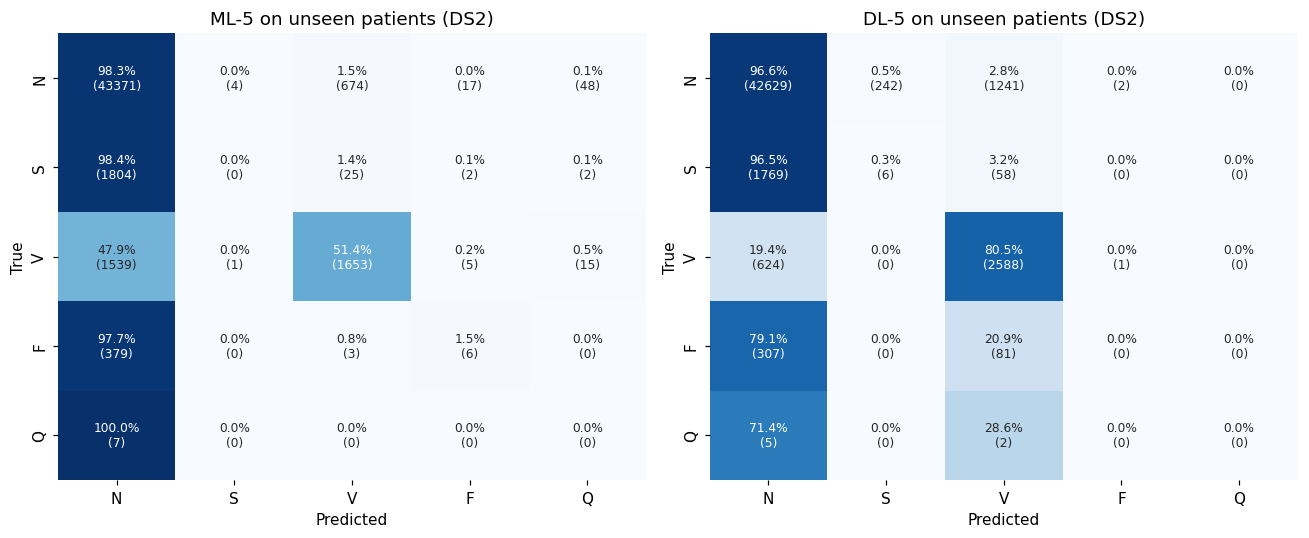

In [6]:
INTRA = {  # main notebook, Section 8 test results (Kaggle intra-patient split)
    "ML-5": {"accuracy": 0.9820, "balanced_acc": 0.8631, "macro_f1": 0.9014, "macro_auc": 0.9933,
             "recall_N": 0.9971, "recall_S": 0.7068, "recall_V": 0.9385, "recall_F": 0.6975, "recall_Q": 0.9757},
    "DL-5": {"accuracy": 0.9855, "balanced_acc": 0.9387, "macro_f1": 0.9242, "macro_auc": 0.9947,
             "recall_N": 0.9918, "recall_S": 0.8471, "recall_V": 0.9634, "recall_F": 0.9012, "recall_Q": 0.9900}}

inter_cmp = pd.DataFrame({"ML-5 intra-patient (Kaggle test)": INTRA["ML-5"],
                          "ML-5 inter-patient (DS2)": evaluate_predictions(y_p2, proba_ml),
                          "DL-5 intra-patient (Kaggle test)": INTRA["DL-5"],
                          "DL-5 inter-patient (DS2)": evaluate_predictions(y_p2, proba_dl)})
inter_cmp["ML-5 change"] = inter_cmp.iloc[:, 1] - inter_cmp.iloc[:, 0]
inter_cmp["DL-5 change"] = inter_cmp.iloc[:, 3] - inter_cmp.iloc[:, 2]
inter_cmp.to_csv(os.path.join(DIRS["results"], "inter_patient_comparison.csv"))
display(inter_cmp.round(4))

for name, proba in [("ML-5", proba_ml), ("DL-5", proba_dl)]:
    print(f"\n===== {name} on unseen patients (DS2) =====")
    print(classification_report(y_p2, proba.argmax(1), labels=range(N_CLASSES), target_names=SHORT, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_cm(axes[0], y_p2, proba_ml.argmax(1), "ML-5 on unseen patients (DS2)")
plot_cm(axes[1], y_p2, proba_dl.argmax(1), "DL-5 on unseen patients (DS2)")
plt.tight_layout(); savefig("fig13_inter_patient_confusion.png"); plt.show()

Both models collapse on new patients. Macro-F1 falls from 0.901 to 0.315 for ML-5 and from 0.924 to 0.336
for DL-5, yet accuracy still shows about 91%, which is the accuracy trap from the main notebook in its clearest form.

- **S beats fail completely** (recall 0.000 and 0.003). An S beat is defined by arriving early, and a single beat doesn't
  carry its timing relative to its neighbours. On the training patients, the models found S beats through patient-specific
  cues instead, and those don't transfer.
- **F beats fail too** (0.016 and 0.000). Fusion beats are rare and come from very few patients, so there is little general
  shape to learn.
- **DL-5 generalises much better on V beats** (recall 0.81 vs 0.51, macro AUC 0.85 vs 0.75). V beats are defined by their
  wide, unusual shape, and the CNN learned that shape rather than the patient.

DL-5 also stopped early here (best epoch 9 of 15), which suggests the held-out patients looked different enough that extra
training didn't help.

## 7. Results per patient

Accuracy on each DS2 patient, plus recall on that patient's abnormal beats (S, V and F together). A single averaged score can
hide a model that works for some people and fails for others.

,beats,abnormal beats,ML-5 accuracy,ML-5 abnormal recall,DL-5 accuracy,DL-5 abnormal recall
record,,,,,,
100,2265,34,0.985,0.000,0.982,0.029
103,2078,2,0.999,0.000,0.996,0.000
105,2565,46,0.978,0.174,0.959,0.609
111,2118,1,0.963,1.000,0.815,1.000
113,1789,6,0.990,0.000,0.989,0.000
117,1530,1,0.834,0.000,0.938,0.000
121,1856,2,0.994,0.500,0.984,0.500
123,1513,3,0.998,0.000,0.996,0.000
200,2593,858,0.742,0.225,0.938,0.816


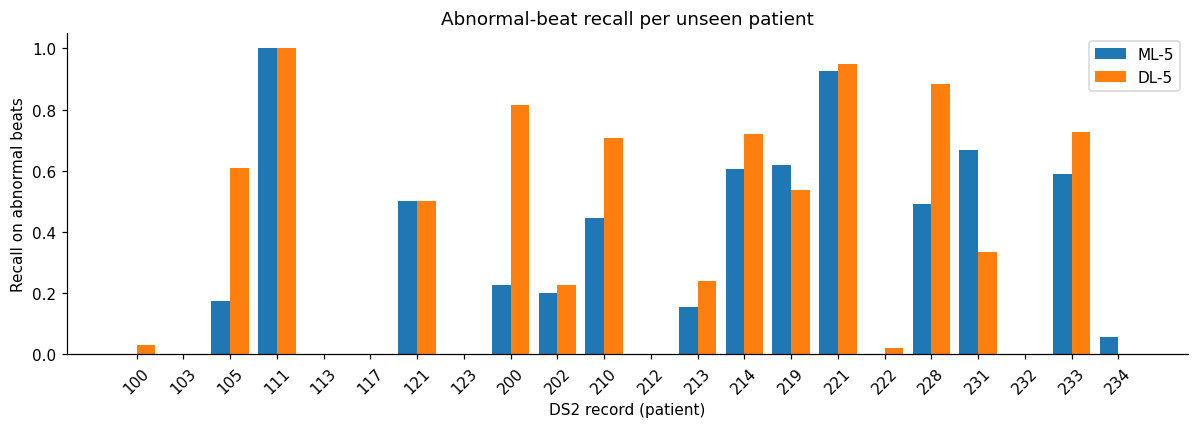

In [7]:
rows = []
for rec in DS2:
    m = pid_p2 == rec
    abn = m & (y_p2 != 0)
    row = {"record": rec, "beats": int(m.sum()), "abnormal beats": int(abn.sum())}
    for name, proba in [("ML-5", proba_ml), ("DL-5", proba_dl)]:
        pred = proba.argmax(1)
        row[f"{name} accuracy"] = (pred[m] == y_p2[m]).mean()
        row[f"{name} abnormal recall"] = (pred[abn] == y_p2[abn]).mean() if abn.sum() else np.nan
    rows.append(row)
per_patient = pd.DataFrame(rows).set_index("record")
per_patient.to_csv(os.path.join(DIRS["results"], "inter_patient_per_record.csv"))
display(per_patient.round(3))

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(per_patient))
ax.bar(x - 0.2, per_patient["ML-5 abnormal recall"], 0.4, label="ML-5")
ax.bar(x + 0.2, per_patient["DL-5 abnormal recall"], 0.4, label="DL-5")
ax.set_xticks(x); ax.set_xticklabels(per_patient.index, rotation=45)
ax.set_xlabel("DS2 record (patient)"); ax.set_ylabel("Recall on abnormal beats")
ax.set_title("Abnormal-beat recall per unseen patient"); ax.legend()
plt.tight_layout(); savefig("fig14_inter_patient_per_record.png"); plt.show()

The failures are concentrated in a few patients. Record 232 alone has 1,379 of DS2's abnormal beats (almost
all S), and both models score about 22% accuracy there because they call nearly every beat normal. Where abnormal beats are
mostly ventricular, DL-5 is far ahead: record 200 (0.82 vs 0.23 abnormal recall) and record 228 (0.88 vs 0.49). Record 222
fails for both models.

## 8. Save

The two retrained models, both result tables, figures 13-14 and the TensorBoard log of the DL run, ready for the Google
Drive folder.

In [8]:
shutil.make_archive(os.path.join(OUT_DIR, "inter_patient_logs"), "zip", DIRS["logs"])
for root, _, files in os.walk(OUT_DIR):
    if "mitdb" in root or "logs" in root:
        continue
    for fn in sorted(files):
        path = os.path.join(root, fn)
        print(f"{os.path.relpath(path, OUT_DIR):50s} {os.path.getsize(path) / 1e6:7.2f} MB")

__notebook__.ipynb                                    0.20 MB
inter_patient_logs.zip                                0.00 MB
models/INTER-DL5.keras                                2.14 MB
models/INTER-ML5.joblib                               0.32 MB
results/inter_patient_comparison.csv                  0.00 MB
results/inter_patient_per_record.csv                  0.00 MB
figures/fig13_inter_patient_confusion.png             0.10 MB
figures/fig14_inter_patient_per_record.png            0.04 MB


## 9. Conclusion

The headline scores in the main notebook (about 0.9 macro-F1) mostly measure how well the models recognise patients they have
already seen. On new patients both drop to about 0.3, which matches the shortcut risk I flagged during exploration: the
strongest feature, beat length, partly describes each recording's heart rate.

The deep model holds up better where the arrhythmia is a matter of shape (V beats), and both fail where it is a matter of
timing (S beats). To close the gap I would add RR-interval features from the neighbouring beats, train on more and more
diverse patients (including African data), and try patient-specific fine-tuning (Kiranyaz et al., 2016).